# Inteligência Artificial – 2025/2026
## Projeto – Grupo 1 - Pesquisa Adversarial e Árvores de Decisão no PopOut

**Membros do Grupo:**
- Alice Silva
- Lara Neiva Carvalho
- Ana Sofia Santos

# PopOut, MCTS e Árvores de Decisão ID3

Este notebook está estruturado em **três partes principais**, combinando os conceitos de Monte Carlo Tree Search e Decision Trees aplicadas ao jogo **PopOut**, uma variante do "Connect 4":

- **1. Jogo PopOut e Monte Carlo Tree Search (MCTS):**  
  Implementámos o jogo *PopOut* em Python, incluindo a lógica do jogo e a interface em terminal. Nós desenvolvemos um agente inteligente com base no **Monte Carlo Tree Search (MCTS)** recorrendo à **fórmula UCT** (Upper Confidence Bound for Trees) que classificámos como Monte Carlo base/puro. Depois, aplicámos **heurísticas específicas do domínio** para guiar a simulação, e um **fator de desconto** na retropropagação. Este tem três níveis de dificuldade: Fácil, Médio e Difícil.

- **2. Agentes com Árvore de Decisão ID3:**  
  Neste tópico é possível analisar duas etapas:
  1. Começámos por aplicar a Árvore de Decisão implementada de raíz e aplicámos inicialmente ao **dataset Iris** para perceber o sua aplicabilidade recorrendo a um dataset mais simples.
  1. Depois, treinámos com dados gerados através de jogos entre diversos níveis de dificuldade do algoritmo MCTS. A árvore aprende a imitar as decisões do MCTS em estados do tabuleiro do PopOut.

- **3. Análise de Desempenho do MCTS:**  
  Uma estrutura de torneio simula múltiplos jogos entre agentes MCTS de diferentes níveis de dificuldade e produz visualizações sobre taxas de vitória, custo computacional por jogada e distribuição de tipos de jogadas (drop vs. pop).

# 1. Jogo PopOut e Monte Carlo Tree Search (MCTS)

Esta secção abrange a implementação do jogo **PopOut** e o desenvolvimento de um agente inteligente baseado em **MCTS**. Incluímos a lógica completa do jogo, simulação guiada por heurísticas e o algoritmo MCTS completo.

## 1.1 Imports

Import de todas as bibliotecas necessárias.

In [26]:
import math
import random
import logging
import os
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from collections import defaultdict, Counter

# Configuração visual para parecer um trabalho académico limpo
plt.style.use('ggplot')
sns.set_palette("muted")

## 1.2 Regras e Lógica do Jogo PopOut

**PopOut** é uma variante do *"Connect 4"* jogado numa grelha 6×7. O objetivo é alinhar **quatro peças** horizontal, vertical ou diagonalmente. Ao contrário do Connect 4 padrão, cada jogador pode também usar uma jogada de **pop**:

- **Drop (`drop`):** Colocar a tua peça em qualquer coluna que não esteja cheia. A peça cai para a linha mais baixa disponível.
- **Pop (`pop`):** Remover a tua própria peça da **base** de qualquer coluna onde a tua peça se encontre nessa posição. Todas as peças dessa coluna descem uma linha.

### Regras especiais:
- Um jogador só pode fazer pop da sua **própria** peça na base.
- Se ambos os jogadores atingirem quatro em linha em simultâneo (o que pode acontecer após um pop), o **jogador que moveu** vence.
- O jogo termina em empate se o tabuleiro estiver cheio sem jogadas válidas, ou se o mesmo estado do tabuleiro se repetir **três vezes** (empate por repetição tripla).

### Métodos principais em `PopOut`:
- `get_valid_moves()` : devolve todos os pares possíveis `(tipo_de_jogada, coluna)` para o jogador atual.
- `make_move(tipo, col)` : aplica a jogada e devolve o vencedor (0 = sem vencedor ainda, -1 = empate, 1 ou 2 = jogador vencedor).
- `check_winner(último_jogador)` : deteta quatro em linha para ambos os jogadores, tratando vitórias simultâneas.
- `clone()` : devolve uma cópia profunda do estado do jogo para simulações.

In [27]:
class PopOut:
    # Direções para 4-em-linha: horizontal, vertical, diagonal \, diagonal /
    _DIRECTIONS = ((0, 1), (1, 0), (1, 1), (1, -1))

    def __init__(self):
        self.ROWS = 6
        self.COLS = 7
        self.board = [[0 for _ in range(self.COLS)] for _ in range(self.ROWS)]
        self.current_player = 1
        self.state_history = {}
        self._track_history = True
        self._record_state()

    def print_board(self):
        symbols = {0: " . ", 1: " X ", 2: " O "}
        header = "  " + "   ".join([str(i) for i in range(self.COLS)])
        print("\n" + header)
        print(" ┌" + "───┬" * (self.COLS - 1) + "───┐")
        for i, row in enumerate(self.board):
            row_str = " │" + "│".join([symbols[cell] for cell in row]) + "│"
            print(row_str)
            if i < self.ROWS - 1:
                print(" ├" + "───┼" * (self.COLS - 1) + "───┤")
        print(" └" + "───┴" * (self.COLS - 1) + "───┘")
        print(f" Vez do Jogador: {'X' if self.current_player == 1 else 'O'}")

    def get_valid_moves(self):
        moves = []
        bottom = self.ROWS - 1
        cp = self.current_player
        for col in range(self.COLS):
            if self.board[0][col] == 0:
                moves.append(('drop', col))
            if self.board[bottom][col] == cp:
                moves.append(('pop', col))

        #se nao houver drops possiveis (tabuleiro cheio no topo)
        #o jogador pode optar por declarar empate em vez de fazer pop
        if self.is_board_full():
            moves.append(('draw', None))
        return moves

    def _is_legal_move(self, move_type, col):

        if move_type == 'draw':
            return self.is_board_full()
        
        if not isinstance(col, int) or col < 0 or col >= self.COLS:
            return False
        if move_type == 'drop':
            return self.board[0][col] == 0
        if move_type == 'pop':
            return self.board[self.ROWS - 1][col] == self.current_player
        return False

    def make_move(self, move_type, col):
        if not self._is_legal_move(move_type, col):
            raise ValueError(f"Jogada ilegal: ({move_type}, {col}).")

        if move_type == 'draw':
            self._record_state()
            return -1 # retorna empate imediato por decisao do jogador
        
        last_player = self.current_player

        if move_type == 'drop':
            # Encontrar linha de aterragem
            landing = -1
            for r in range(self.ROWS - 1, -1, -1):
                if self.board[r][col] == 0:
                    self.board[r][col] = last_player
                    landing = r
                    break
            # OTIMIZAÇÃO: só o jogador que dropou pode ter completado um 4.
            # Verificação local em torno da célula onde aterrou.
            if self._has_four_through(landing, col, last_player):
                winner = last_player
            else:
                winner = 0

        else:  # pop
            for r in range(self.ROWS - 1, 0, -1):
                self.board[r][col] = self.board[r - 1][col]
            self.board[0][col] = 0
            # OTIMIZAÇÃO: pop só altera uma coluna. Ambos os jogadores podem
            # ter novos 4s, mas só verificamos linhas que passem por essa coluna.
            winner = self._check_after_pop(col, last_player)

        if winner != 0:
            self.current_player = 3 - self.current_player
            self._record_state()
            return winner

        self.current_player = 3 - self.current_player
        self._record_state()

        if self._track_history and self.is_repetition_draw():
            return -1
        if not self.get_valid_moves():
            return -1
        return 0

    def _has_four_through(self, row, col, p):
        """
        Verifica se (row, col) faz parte de um 4-em-linha do jogador p.
        Para cada uma das 4 direções, conta peças consecutivas para ambos os
        lados a partir de (row, col). Se a contagem chegar a 4, há 4-em-linha.
        """
        if row < 0 or self.board[row][col] != p:
            return False
        rows = self.ROWS
        cols = self.COLS
        board = self.board
        for dr, dc in self._DIRECTIONS:
            count = 1
            # Para a frente
            r, c = row + dr, col + dc
            while 0 <= r < rows and 0 <= c < cols and board[r][c] == p:
                count += 1
                r += dr
                c += dc
            # Para trás
            r, c = row - dr, col - dc
            while 0 <= r < rows and 0 <= c < cols and board[r][c] == p:
                count += 1
                r -= dr
                c -= dc
            if count >= 4:
                return True
        return False

    def _check_after_pop(self, col, last_player):
        """
        Após um pop em col, qualquer célula dessa coluna pode integrar um novo 4.
        Verifica linha a linha. Resolve empates (ambos com 4) a favor do jogador
        que acabou de jogar — preserva a regra original de check_winner.
        """
        p1_win = False
        p2_win = False
        for r in range(self.ROWS):
            cell = self.board[r][col]
            if cell == 1 and not p1_win and self._has_four_through(r, col, 1):
                p1_win = True
            elif cell == 2 and not p2_win and self._has_four_through(r, col, 2):
                p2_win = True
            if p1_win and p2_win:
                break
        if p1_win and p2_win:
            return last_player
        if p1_win:
            return 1
        if p2_win:
            return 2
        return 0

    def _record_state(self):
        if not self._track_history:
            return
        state_key = (tuple(tuple(row) for row in self.board), self.current_player)
        self.state_history[state_key] = self.state_history.get(state_key, 0) + 1

    def is_repetition_draw(self):
        if not self._track_history:
            return False
        state_key = (tuple(tuple(row) for row in self.board), self.current_player)
        return self.state_history.get(state_key, 0) >= 3

    def top_row_full(self):
        return all(self.board[0][col] != 0 for col in range(self.COLS))

    def is_board_full(self):
        return self.top_row_full()

    def check_winner(self, last_player):
        """
        Mantido por retrocompatibilidade — faz scan completo. NÃO é usado pelo
        novo make_move (que usa as verificações locais acima). Útil se algum
        outro código (ex. dataset generation) ainda chamar diretamente.
        """
        p1 = self._has_four(1)
        p2 = self._has_four(2)
        if p1 and p2:
            return -1
        if p1:
            return 1
        if p2:
            return 2
        return 0

    def _has_four(self, p):
        # Versão "lenta" preservada apenas para check_winner externo.
        for r in range(self.ROWS):
            for c in range(self.COLS - 3):
                if all(self.board[r][c + i] == p for i in range(4)):
                    return True
        for r in range(self.ROWS - 3):
            for c in range(self.COLS):
                if all(self.board[r + i][c] == p for i in range(4)):
                    return True
        for r in range(self.ROWS - 3):
            for c in range(self.COLS - 3):
                if all(self.board[r + i][c + i] == p for i in range(4)):
                    return True
        for r in range(3, self.ROWS):
            for c in range(self.COLS - 3):
                if all(self.board[r - i][c + i] == p for i in range(4)):
                    return True
        return False

    def clone(self):
        new_game = PopOut.__new__(PopOut)
        new_game.ROWS = self.ROWS
        new_game.COLS = self.COLS
        new_game.board = [row[:] for row in self.board]
        new_game.current_player = self.current_player
        new_game.state_history = {}
        new_game._track_history = False
        return new_game

### Demonstração Rápida do Estado do Jogo

Visualização de um tabuleiro inicial e teste do sistema de jogadas:

In [28]:
demo = PopOut()
print("Tabuleiro initial:")
demo.print_board()
print("\nValid moves for Player 1 (first few):", demo.get_valid_moves()[:5], "...")

# Drop in center, then show board
demo.make_move('drop', 3)
demo.make_move('drop', 3)
print("\nAfter two drops in column 3:")
demo.print_board()

Tabuleiro initial:

  0   1   2   3   4   5   6
 ┌───┬───┬───┬───┬───┬───┬───┐
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 └───┴───┴───┴───┴───┴───┴───┘
 Vez do Jogador: X

Valid moves for Player 1 (first few): [('drop', 0), ('drop', 1), ('drop', 2), ('drop', 3), ('drop', 4)] ...

After two drops in column 3:

  0   1   2   3   4   5   6
 ┌───┬───┬───┬───┬───┬───┬───┐
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ O │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ X │ . 

## 1.3 Monte Carlo Tree Search (MCTS) – Teoria

O **Monte Carlo Tree Search (MCTS)** é um algoritmo de tomada de decisão que constrói incrementalmente uma árvore de pesquisa, simulando jogos aleatórios (ou guiados por heurísticas) e propagando os resultados pela árvore. Incialmente recorremos aos aspetos teóricos abordados nas aulas da respetiva unidade curricular para desenvolver uma versão do MCTS puro sem qualquer tipo de otimizações e depois decidimos aplicar otimizações e heurísticas para melhorar a sua performance e adaptar ao jogo em questão.

### As Quatro Fases

Cada iteração do MCTS consiste em quatro fases:

1. **Seleção** : A partir da raiz, escolher repetidamente o filho com o maior **score UCB** até chegar a um nó com filhos por explorar ou a um estado terminal.

2. **Expansão** : Adicionar um novo nó filho aplicando uma jogada inexplorada ao estado atual.

3. **Simulação (Rollout/Playout)** : Jogar o resto da partida a partir do novo nó usando uma política de simulação (aleatória ou guiada por heurísticas) até atingir um estado terminal.

4. **Retropropagação** : Propagar o resultado da simulação de volta por todos os nós anteriores, atualizando contagens de visitas e estatísticas de vitórias.

### Fórmula UCB

Para selecionar qual filho visitar durante a fase de **Seleção**, usamos a fórmula **UCB (Upper Confidence Bound for Trees)**:

$$UCB(v, c) = \frac{w_v}{n_v} + C \cdot \sqrt{\frac{\ln N_{parent}}{n_v}}$$

Onde:
- $w_v$ = vitórias acumuladas do nó $v$
- $n_v$ = contagem de visitas do nó $v$
- $N_{parent}$ = contagem de visitas do nó pai
- $C$ = constante de exploração (em geral considerámos $\sqrt{2} \approx 1.414$)

Uma das características mais relevantes da fórmula é o equilíbrio entre a fase de Exploitation e de Exploration sendo que a primeira enfatiza/beneficia os nós que já provaram anteriormente trazer resultados mais favoráveis enquanto que a segunda parte da soma permite valorizar a exploração de nós que, até ao momento, ainda não foram bem explorados, mas que até podem ser nós muito interessantes a selecionar.

### Melhorias na Nossa Implementação

Para além do MCTS padrão, implementámos várias melhorias:

| Melhoria | Descrição |
|---|---|
| **Simulação heurística** | Três políticas de simulação: `random`, `light` (consciente de sequências, pesos moderados), `heavy` (consciente de sequências, pesos exponenciais) |
| **Fator de desconto (γ = 0.95)** | A retropropagação recompensa vitórias mais rápidas relativamente a vitórias mais lentas, e penaliza derrotas lentas mais do que derrotas rápidas |
| **Visão tática (lookahead de 3 camadas)** | Antes do MCTS: verificar vitórias imediatas, bloquear vitórias imediatas do adversário, e detetar ameaças duplas forçadas a 2 jogadas |
| **Parâmetro C dinâmico** | O Jogador 1 usa um C mais baixo (focado em exploração); o Jogador 2 usa um C mais alto (focado em exploration) |
| **Seleção probabilística (modo Fácil)** | O modo Fácil escolhe aleatoriamente entre os top-3 filhos em vez de escolher sempre o melhor |

## 1.4 MCTS Puro (Linha de Base, Sem Heurísticas)

Para fins de comparação, implementámos também um agente **MCTS puro** sem quaisquer melhorias:
- UCT padrão com $C = \sqrt{2}$
- Rollouts completamente aleatórios (sem orientação heurística)
- Sem visão tática / lookahead
- Sem fator de desconto : contagens de vitórias brutas na retropropagação

Serve como linha de base para comparação com o MCTS melhorado com heurísticas.

In [29]:
class MCTSNodePure:
    """
    Pure MCTS node — no heuristics of any kind
    Selection uses standard UCT (c = sqrt(2))
    Simulation uses fully random rollouts
    Backpropagation uses raw win counts (no discount factor)
    """

    def __init__(self, state, parent=None, move=None):
        self.state = state
        self.parent = parent
        self.move = move

        self.children = []
        self.visits = 0
        self.wins = defaultdict(float) 
        self.untried_moves = self.state.get_valid_moves()
        random.shuffle(self.untried_moves)

    def is_fully_expanded(self):
        return len(self.untried_moves) == 0

    def best_child(self, c_param=1.414):
        player = self.state.current_player
        best_score = -float('inf')
        best = None
        for child in self.children:
            if child.visits == 0:
                return child  # visit unvisited children first
            win_rate = child.wins[player] / child.visits
            exploration = c_param * math.sqrt(math.log(self.visits) / child.visits)
            score = win_rate + exploration
            if score > best_score:
                best_score = score
                best = child
        return best

    def expand(self):
        move = self.untried_moves.pop(0)
        next_state = self.state.clone()
        next_state.make_move(*move)
        child = MCTSNodePure(next_state, parent=self, move=move)
        self.children.append(child)
        return child

    def simulate(self):
        #Fully random rollout — no weights, no lookahead
        temp_state = self.state.clone()

        # expand() ignores the return value of make_move, so if the expansion
        # move was a winning move the board already has 4-in-a-row. make_move
        # inside the loop only detects NEW wins, so we must catch this here.
        last_player = 3 - temp_state.current_player
        winner = temp_state.check_winner(last_player)
        if winner != 0:
            return winner

        while True:
            valid_moves = temp_state.get_valid_moves()
            if not valid_moves:
                return -1  # draw
            move = random.choice(valid_moves)
            result = temp_state.make_move(*move)
            if result != 0:
                return result

    def backpropagate(self, result):
        self.visits += 1
        if result == -1:
            # draw: credit both players equally
            self.wins[1] += 0.5
            self.wins[2] += 0.5
        else:
            self.wins[result] += 1.0
        if self.parent:
            self.parent.backpropagate(result)


def get_mcts_pure_move(game_state, iterations=1000):
    """
    Pure MCTS with no heuristics.
    - c = sqrt(2) (standard UCT constant)
    - Random rollouts
    - No tactical vision / 1-step lookahead
    - Final move selected by most visits (robust child criterion)
    """
    root = MCTSNodePure(game_state.clone())

    for _ in range(iterations):
        node = root

        # 1. Selection
        while not node.untried_moves and node.children:
            node = node.best_child(c_param=1.414)

        # 2. Expansion
        if node.untried_moves:
            node = node.expand()

        # 3. Simulation
        result = node.simulate()

        # 4. Backpropagation
        node.backpropagate(result)

    # Pick the most-visited child
    return max(root.children, key=lambda c: c.visits).move

## 1.5 Política de Simulação Heurística

Em vez de escolher jogadas aleatórias durante os rollouts, usamos conhecimento do domínio para guiar a simulação:

- **`random`**: Escolhe qualquer jogada possível de forma uniformemente aleatória.
- **`light`**: Prefere colunas centrais e peças adjacentes às existentes (tendência suave).
- **`heavy`**: Prefere fortemente estender as próprias sequências e bloquear as do adversário — usado no modo Difícil.

As jogadas de pop recebem pesos mais baixos pois são menos frequentemente benéficas nas fases iniciais.

In [30]:
DIRECOES = ((0, 1), (1, 0), (1, 1), (1, -1))

# Função auxiliar de "exploração". "Caminha" numa só direção e conta quantas peças seguidas do mesmo tipo há
# Argumentos dados: posição atual, direção do movimento, qual a peça que estamos à procura 
def count_sequence(board, row, col, dr, dc, target, rows, cols):
    n = 0
    r = row + dr
    c = col + dc
    while (0 <= r < rows and 0 <= c < cols and board[r][c] == target):
        n += 1
        r += dr
        c += dc
    # Retorono: quantas peças consecutivas há naquela direção (sem contar peça inicial)
    return n

# Objetivo: encontrar a maior sequência numa determinada direção
def maximum_sequence_length(board, landing, col, target, rows, cols):
    best = 0
    for dr, dc in DIRECOES:
        forward  = count_sequence(board, landing, col,  dr,  dc, target, rows, cols)
        backward = count_sequence(board, landing, col, -dr, -dc, target, rows, cols)
        # Soma do nº peças encontradas p a esquerda e p a direita
        total = forward + backward
        if total > best:
            best = total
    # Retorno do comprimento da maior linha encontrada (continuamos sem contabilizar a peça em questão)
    return best

# Escolha da heurística
def heuristic_choice(game, moves, heur_type):
    # Nível aleatório
    if heur_type == 'random':
        return random.choice(moves)

    board = game.board
    rows = game.ROWS
    cols_count = game.COLS
    # Cálculo de qual a coluna central
    center = cols_count // 2
    current = game.current_player
    opponent_p = 3 - current

    # Definição de pesos que fomos alterando mediante testes com o algoritmo
    # Os índices, por ex., OWN(0, 1, 2, 3) correspondem ao número de peças já existentes naquela sequência
    # Quando já temos um alinhamento de 3 e somamos 1 peça = Vitoria
    if heur_type == 'heavy':
        # Pesos crescentes e exponenciais para valorização quando há 2 em linha e principalmente 3
        # Pequena vantagem para OWN relativamente a OPP para priorizar vencer o jogo logo em vez de ir bloquear o adversário
        OWN  = (0, 6, 30, 200)
        OPP  = (0, 5, 25, 180)
    else:
        # Pesos um pouco mais moderados
        # Permite que o random.choices escolha jogadas sub-ótimas de vez em quando - usamos para niveis de dif. do jogo mais baixos
        OWN  = (0, 3, 10, 60)
        OPP  = (0, 2,  8, 50)

    weights = []
    # Para cada movimento possível, calcular um peso para ele
    # m_type: pop ou drop e col: qual a coluna deste movimento
    for m_type, col in moves:
        if m_type == 'drop':
            dist_to_center = abs(col - center)
            # Pesos maiores ao centro e garantia que o peso mínimo é 1
            w = max(1, 10 - dist_to_center * 2)

            # Inicialização da variável que guarda o local onde a peça vai ficar - simulação
            landing = None
            # Percorrer a coluna de baixo para cima pois as peças caem. rows-1 até 0
            for r in range(rows - 1, -1, -1):
                if board[r][col] == 0:
                    # Assim que encontra um espaço vazio guarda essa linha e para o ciclo de procura
                    landing = r
                    break
            # Se houver espaço
            if landing is not None:
                # Quantas peças nossas ficam alinhadas se jogarmos ali?
                own_aligned = maximum_sequence_length(board, landing, col, current,    rows, cols_count)
                # Quantas peças do adversário ficam alinhadas se jogarmos ali?
                opp_aligned = maximum_sequence_length(board, landing, col, opponent_p, rows, cols_count)
                
                # min apenas como mecanismo de segurança pois os tuples de OWN e OPP só tem 4 posições (0, 1,2, 3). Assim garantimos que no máximo só tenta aceder à pos. 3
                # Objetivo: quanto é que esta jogada me ajuda a ganhar?
                # Por ex.: Se houver own_aligned = 3 então vai a OWN[3] e por isso soma 200 ao peso w
                w += OWN[min(own_aligned, 3)]
                # Quanto é que esta jogada impede o meu adversário de ganhar?
                # Tambem damos notas altas por bloquear o adversário
                w += OPP[min(opp_aligned, 3)]
            
            # Já somamos o bónus do centro, o bónus do ataque e o bónus de defesa
            weights.append(w)
        
        # Desvalorização do pop
        elif m_type == 'pop':
            weights.append(1 if heur_type == 'heavy' else 2)
        else:
            weights.append(1)

    # Entre as escolhas possíveis escolhemos de forma random mas informada pois damos pesos a cada jogada.
    # Mantemos a não privisibilidade do monte carlo que é não determinístico
    # Como random.choices retorna uma lista, utilizamos [0] p/ extrair qual o moviemnto
    return random.choices(moves, weights=weights, k=1)[0]

## 1.6 Nó e Estrutura da Árvore MCTS

Cada nó da árvore MCTS representa um estado do jogo. Armazena:
- O estado do jogo (`state`)
- O nó pai e a jogada que levou até ele
- Uma lista de nós filhos (`children`)
- Contagem de visitas (`visits`) e resultados acumulados (`results`)
- Jogadas ainda não exploradas

O dicionário `results` usa IDs de jogadores como chaves e valores do tipo float (devido ao fator de desconto). Um empate é armazenado com chave `-1` e valor `0.5`.

In [31]:
class MCTSNode:

    '''
    State: Representa o estado do tabuleiro - representação em array
    Parent: É igual a None para o root e igual ao nó do qual cada nó derivou para os restantes nós
    Children: Contem todas as possíveis ações a partir do nó atual
    Move : É None para o Root e para os restantes é igual à ação efetuada pelo pai
    visits: Número de vezes que o nó atual foi visitado
    Results: Dicionário para guardar as vitórias de P1 como 1, P2 como 2 e Empate como -1
    Untried_actions: Lista de todas as possíveis ações
    Heur_type: qual a heurística a usar
    '''
    def __init__(self, state, parent=None, move=None, heur_type='light'):
        self.state = state
        self.parent = parent
        self.move = move
        self.children = []
        self.visits = 0
        self.results = defaultdict(float)
        self.untried_moves = self.state.get_valid_moves()
        # Para diminuir o bias
        random.shuffle(self.untried_moves)
        self.heur_type = heur_type

    def is_fully_expanded(self):
        return len(self.untried_moves) == 0

    # Equilíbrio entre a Exploitation e a Exploration
    def best_child(self, c_param=1.414):
        # Quem é o player atual? Será que o monte carlo quer ganhar ou evitar que o oponente ganhe?
        player_to_optimize = self.state.current_player
        # Inicialização a - infinito para garantir que qualquer 1ª jogada avaliada é maior que isso
        best_score = -float('inf')
        # best vai guardar o nó vencedor
        best = None
        # Percorrer todas as jogadas possíveis a partir do nó atual
        for child in self.children:
            # Se houver ainda algum filho não testado começar por esse
            if child.visits == 0:
                return child

            # Qual a taxa de vitórias desta jogada tendo em conta o nr vezes que foi simulada? Quanto maior melhor
            win_rate = child.results[player_to_optimize] / child.visits
            # Exploration: Qual foi a jogada testada menos vezes? Usando a fórmula de UCB
            exploration = c_param * math.sqrt(math.log(self.visits) / child.visits)
            score = win_rate + exploration
            if score > best_score:
                best_score = score
                best = child
        return best

    # Fase 2: EXPANSÃO

    def expand(self):
        move = self.untried_moves.pop(0)
        next_state = self.state.clone()
        # Executa esta mudança na nossa "realidade paralela" pois como ainda estamos a testar, não queremos que altere já no jogo
        next_state.make_move(*move)
        # Criação de um novo nó para guardar esse novo futuro na nossa árvore
        child = MCTSNode(next_state, parent=self, move=move, heur_type=self.heur_type)
        self.children.append(child)
        return child

    # SIMULAÇÃO
    def simulate(self):
        # Se escolhermos este caminho, será que leva a vitória?
        # Para responder vai jogar o resto para ver qual seria o resultado
        
        # Continuar a garantir que não há alterações no tabuleiro verdadeiro
        temp_state = self.state.clone()
        depth = 0
        # "Jogo Imaginário"
        while True:
            valid_moves = temp_state.get_valid_moves()
            if not valid_moves:
                return -1, depth # Empate
            
            # Utilização de heurística para ser melhor que aleatório
            move = heuristic_choice(temp_state, valid_moves, self.heur_type)
            res = temp_state.make_move(*move)
            depth += 1
            if res != 0:
                return res, depth

    # A função recebe o resultado da simulação
    def backpropagate(self, result, playout_depth):
        self.visits += 1
        # Caso a jogada tenha terminado em empate
        if result == -1:
            self.results[1] += 0.5
            self.results[2] += 0.5
        else:
            #Fator de recompensa com desconto
            # playout_depth indica qnts movimentos foram necessários na simulação até à vitória
            discount = 0.95 ** playout_depth
            self.results[result] += discount
        if self.parent:
            self.parent.backpropagate(result, playout_depth)

## 1.7 Função de Seleção de Jogada MCTS

Decidimos também implementar um processo de decisão de forma a que, se houver alguma jogada óbvia a fazer, não seja necessário simular cenários mais complexos:
1. Aplicar **visão tática** (`tactical_choice`) : Verificação se é possível ganhar imediatamente, se precisa de bloquear o adversário ou se existem ameaças duplas. Caso encontre algum resultado imediato através desta função, a jogada é logo efetuada o que faz com que não seja necessário utilizar processamento extra. Optámos por manter a visão tática (use_tactical_vision = True) mesmo no modo de dificuldade facil, uma vez que mesmo um jogador humano inexperiente ou 'fraco' consegue identificar uma vitória imediata óbvia ou a necessidade urgente de bloquear o adversário no próximo turno. Remover esta capacidade não simularia um jogador fraco, mas sim um jogador a jogar de forma completamente aleatória e 'às cegas', o que não reflete o comportamento real de um principiante.

Para além disso:

Executa o ciclo MCTS durante um número configurado de iterações e de acordo com as seguintes definições de níveis de dificuldade.

### Configurações de Dificuldade

| Nível | Iterações | Simulação | Parâmetro C | Seleção |
|---|---|---|---|---|
| Fácil | 150 | Aleatório | 2.5 (fixo) | Seleção aleatória entre 0s 3 melhores|
| Médio | 1000 | Light | 1.2 / 1.6 (dinâmico) | Mais visitado |
| Difícil | 10 000 | Heavy | 0.96 / 1.28 (dinâmico) | Mais visitado |

In [32]:
def count_immediate_wins(state, player):
    """Quantas jogadas em 'state' permitem 'player' ganhar imediatamente?"""
    # Queremos saber quando temos uma vitória garantida ou quando o oponente tem uma vitória logo que iria acabar o jogo se não bloqueássemos
    # Garantir que 'state' tem o player certo a jogar
    if state.current_player != player:
        #De forma a conseguirmos trocar o jogador atual sem realmente "estragar" o jogo verdadeiro
        state = state.clone()
        state.current_player = player
    # Inicializa o contador de vitórias imediatas
    n = 0
    for mv in state.get_valid_moves():
        t = state.clone()
        try:
            # Se a jogada levar a vitória somamos 1 ao contador
            if t.make_move(*mv) == player:
                n += 1
        except ValueError:
            continue
    return n


def opponent_can_force_win(state_after_my_move, opponent, me):
    """
    Quer saber: se eu jogar aqui o que é que o adversário pode fazer?
    Após a minha jogada, o adversário tem alguma resposta que crie uma
    ameaça dupla (ou superior) 

    Devolve True se sim. Esta é a deteção de "ameaça a 2 jogadas".
    """
    for opp_move in state_after_my_move.get_valid_moves():
        t = state_after_my_move.clone()
        try:
            res = t.make_move(*opp_move)
        except ValueError:
            continue
        if res == opponent:
            # Adversário ganha já com esta jogada — também é ameaça forçada,
            # mas através da outra função já teriamos apanhado esta ameaça logo não precisamos repetir
            return True
        if res == -1 or res == me:
            # Empate ou vitória nossa: o adversário não tem ameaça
            continue
        # 'res == 0': jogo continua. É a minha vez de novo
        # Mas estamos a perguntar se o ADVERSÁRIO conseguiu criar ameaça
        # dupla, e a ameaça dupla mede-se pela contagem de vitórias DELE
        # depois da MINHA próxima jogada. Como a próxima a jogar sou eu,
        # eu vou tentar bloquear. Logo a verdadeira pergunta é:
        #
        #   "Existe alguma jogada minha que neutralize TODAS as vitórias
        #    do adversário a partir deste novo estado?"
        #
        # Se não existe, então o adversário forçou a vitória
        my_state = t  # vez de eu jogar
        # Para cada jogada minha, conta quantas vitórias do adversário sobram.
        worst_case = None
        for my_move in my_state.get_valid_moves():
            t2 = my_state.clone()
            try:
                r2 = t2.make_move(*my_move)
            except ValueError:
                continue
            if r2 == me:
                worst_case = 0  # se eu ganhei então significa que a ameaça neutralizada
                break
            opp_wins_after = count_immediate_wins(t2, opponent)
            if worst_case is None or opp_wins_after < worst_case:
                worst_case = opp_wins_after
            if worst_case == 0:
                break
        if worst_case is not None and worst_case > 0:
            # Para esta jogada do adversário, o melhor que conseguimos
            # ainda deixa pelo menos 1 vitória dele no ply seguinte
            # Logo o adversário forçou a vitória
            return True
    return False


def tactical_choice(game_state, valid_moves):
    """
    Visão tática estendida recorrendo a diversas etapas
    Camadas:
      1. tenho vitória imediata?
      2. alguma jogada minha previne vitória adversária imediata?
      3 além disso, alguma jogada minha previne que o adversário FORCE a vitória na jogada seguinte (criação de ameaça dupla)?

    """
    current = game_state.current_player
    opponent = 3 - current

    # 1. Tenho vitória imediata?
    for move in valid_moves:
        test = game_state.clone()
        try:
            if test.make_move(*move) == current:
                return ('forced', move)
        except ValueError:
            continue

    # 2. classifica jogadas pelo nº de vitórias imediatas do
    # adversário que sobram a seguir
    move_threats_1ply = []
    for move in valid_moves:
        my_clone = game_state.clone()
        try:
            result = my_clone.make_move(*move)
        except ValueError:
            continue
        if result == current or result == -1:
            move_threats_1ply.append((move, 0, my_clone, result))
            continue
        threats = count_immediate_wins(my_clone, opponent)
        move_threats_1ply.append((move, threats, my_clone, result))

    if not move_threats_1ply:
        return ('none', None)

    min_1ply = min(t for _, t, _, _ in move_threats_1ply)

    if min_1ply > 0:
        # Adversário tem vitória forçada já — escolher menos mau
        least_bad = [m for m, t, _, _ in move_threats_1ply if t == min_1ply]
        if len(least_bad) == 1:
            return ('forced', least_bad[0])
        return ('safe_set', least_bad)

    # Há jogadas que neutralizam ameaças imediatas: então filtra-las
    safe_1ply = [(m, s, r) for m, t, s, r in move_threats_1ply if t == 0]

    # 3. entre as jogadas seguras a 1 ply, quais permitem que o
    # adversário FORCE vitória no ply seguinte? Eliminá-las
    truly_safe = []
    for move, state_after, result in safe_1ply:
        if result == current or result == -1:
            # Jogada que termina o jogo já — totalmente segura.
            truly_safe.append(move)
            continue
        if not opponent_can_force_win(state_after, opponent, current):
            truly_safe.append(move)

    if len(truly_safe) == 1:
        return ('forced', truly_safe[0])
    if len(truly_safe) > 1:
        return ('safe_set', truly_safe)

    # Todas as jogadas seguras a 1 ply permitem ameaça dupla a 2 plies
    # Não há salvação garantida — devolvemos as 1-ply-safe e o MCTS escolhe.
    safe_moves_only = [m for m, _, _ in safe_1ply]
    if len(safe_moves_only) == 1:
        return ('forced', safe_moves_only[0])
    return ('safe_set', safe_moves_only)

In [33]:
def get_mcts_move(game_state, dificuldade='medio'):
    valid_moves = game_state.get_valid_moves()
    if not valid_moves:
        return None

    is_player_one = (game_state.current_player == 1)
    base_c_param = 1.2 if is_player_one else 1.6

    if dificuldade == 'facil':
        iterations = 150
        c_param = 2.5
        use_tactical_vision = True
        heur_type = 'random'
    elif dificuldade == 'dificil':
        iterations = 10000
        c_param = base_c_param * 0.8
        use_tactical_vision = True
        heur_type = 'heavy'
    else:
        iterations = 1000
        c_param = base_c_param
        use_tactical_vision = True
        heur_type = 'light'

    candidate_moves = valid_moves
    if use_tactical_vision:
        decision, payload = tactical_choice(game_state, valid_moves)
        if decision == 'forced':
            return payload
        elif decision == 'safe_set':
            candidate_moves = payload

    root = MCTSNode(game_state.clone(), heur_type=heur_type)
    if candidate_moves is not valid_moves:
        root.untried_moves = list(candidate_moves)
        random.shuffle(root.untried_moves)

    for _ in range(iterations):
        node = root
        while not node.untried_moves and node.children:
            node = node.best_child(c_param=c_param)
        if node.untried_moves:
            node = node.expand()
        result, playout_depth = node.simulate()
        node.backpropagate(result, playout_depth)

    if not root.children:
        return random.choice(candidate_moves)

    if dificuldade == 'facil':
        sorted_children = sorted(root.children, key=lambda c: c.visits, reverse=True)
        top_children = sorted_children[:min(3, len(sorted_children))]
        return random.choice(top_children).move
    else:
        return max(root.children, key=lambda c: c.visits).move

### Demonstração Rápida do MCTS

Executamos o agente MCTS (Médio) para uma jogada e observamos a sua escolha:

In [34]:
demo_game = PopOut()
demo_game.print_board()
print("\nRunning MCTS (Medium) for Player 1...")
chosen_move = get_mcts_move(demo_game, dificuldade='medio')
print(f"MCTS chose: {chosen_move}")


  0   1   2   3   4   5   6
 ┌───┬───┬───┬───┬───┬───┬───┐
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 ├───┼───┼───┼───┼───┼───┼───┤
 │ . │ . │ . │ . │ . │ . │ . │
 └───┴───┴───┴───┴───┴───┴───┘
 Vez do Jogador: X

Running MCTS (Medium) for Player 1...
MCTS chose: ('drop', 3)


## 1.8 Avaliação de Performance e Análise de Incerteza

Devido a restrições de tempo de processamento associadas à profundidade do MCTS, os nossos testes iniciais e afinação de parâmetros foram limitados a amostras de $n = 10$ jogos por confronto. Reconhecemos que uma amostra desta dimensão introduz uma margem de erro estatístico considerável na taxa de vitória (win rate).

Para garantir o rigor na avaliação, recorremos ao cálculo de Intervalos de Confiança (com nível de confiança de 95%) para proporções binomiais (Vitória/Não Vitória). Por exemplo, num cenário inicial onde um agente obtém 7 vitórias em 10 jogos (70% de win rate), o intervalo de confiança pelo método de Wilson situa a verdadeira taxa de vitória algures entre 39.7% e 89.2%.

#### Aumento do Rigor Estatístico na Avaliação Final:
Para obtermos um rigor estatístico onde a margem de erro fosse inferior a 5%, necessitaríamos de simular cerca de 400 jogos por confronto. Como isso exigiria dias ininterruptos de computação, decidimos que no Torneio Final de Avaliação (Secção 3.1 deste relatório), aumentámos a amostra para $n = 30$ jogos por confronto. 

Ao passar para 30 jogos, reduzimos substancialmente a incerteza (por exemplo, 28 vitórias em 30 jogos, como veremos mais à frente, garante-nos com 95% de confiança que a *win rate* real é superior a 78.9%). Concluímos assim que os resultados obtidos neste projeto servem como uma forte prova empírica da superioridade das heurísticas aplicadas, validados de forma qualitativa e quantitativa dentro dos recursos computacionais disponíveis.

# 2. Árvore de Decisão ID3

Esta parte abrange duas aplicações distintas do nosso **algoritmo ID3** que implementámos de raíz baseando-nos nas ideias discutidas na unidade curricular:

1. Inicialmente fizemos um "warm-up" para testar a implementação da decision tree recorrendo ao iris dataset providenciado.

2. Depois, gerámos um dataset a partir da implementação anterior do algoritmo MCTS e utilizámos o mesmo para treinar a árvore de decisão.

## 2.1 Algoritmo ID3 :  Teoria

O **ID3 (Iterative Dichotomiser 3)**, introduzido por Ross Quinlan em 1986, constrói uma árvore de decisão selecionando recursivamente o atributo que melhor classifica os dados de treino. Estes são os aspetos mais importantes a considerar e que será possível analisar na implementação em Python apresentada de seguida.

### Entropia

A entropia mede a **impureza** de uma distribuição de classes $S$:

$$H(S) = -\sum_{c \in C} p_c \log_2 p_c$$

onde $p_c$ é a proporção da classe $c$ em $S$. $H(S) = 0$ significa que todos os exemplos pertencem à mesma classe (folha pura).

### Ganho de Informação

O Ganho de Informação mede quanto um atributo $A$ reduz a entropia:

$$IG(S, A) = H(S) - \sum_{v \in V(A)} \frac{|S_v|}{|S|} H(S_v)$$

O ID3 escolhe o atributo com o **maior ganho de informação** em cada nó.

### Construção Recursiva

A árvore é construída recursivamente. Um nó torna-se uma **folha** quando:
- Todos os exemplos nesse nó partilham a mesma classe.
- Não restam atributos para dividir.
- Uma profundidade máxima configurada é atingida.

### Vantagens e Limitações

| Vantagem | Limitação |
|---|---|
| Totalmente interpretável | Overfitting em datasets pequenos/ruidosos |
| Sem afinação de hiperparâmetros além da profundidade | Não suporta valores contínuos nativamente |
| Inferência rápida | Sensível à ordenação dos atributos |
| Funciona diretamente com dados categóricos | Não suporta valores em falta |

## 2.2 Implementação do ID3

A nossa implementação usa uma estrutura recursiva `TreeNode`. A classe `ID3DecisionTree` expõe:
- `fit(data, target_name, features, depth)` : treina a árvore recursivamente.
- `predict_single(node, sample)` : percorre a árvore para um único exemplo.
- `predict(data)` : aplica a predição a um DataFrame completo.
- `plot_tree()` : apresenta a estrutura da árvore graficamente.

In [35]:
class TreeNode:
    def __init__(self, attribute=None, label=None):
        self.attribute = attribute  # Nome do atributo usado para dividir o nó
        self.label = label          # Se for folha, guarda a classe final
        self.children = {}          # Dicionário que guarda o interliga o valor de um atributo ao próximo nó

class ID3DecisionTree:
    def __init__(self, max_depth=None):
        self.root = None
        self.max_depth = max_depth

    def entropy(self, target_col):
        # 1. Calcular a frequência de cada classe uma única vez
        counts = pd.Series(target_col).value_counts().values
        
        # 2. Armazenar o total de elementos para evitar recalculá-lo no loop
        total_elementos = sum(counts)
        
        entropy = 0
        for count in counts:
            # 3. Calcular a probabilidade p(i) da classe atual
            probabilidade = count / total_elementos
            
            # 4. Aplicar a fórmula: -p * log2(p)
            entropy -= probabilidade * math.log2(probabilidade)
            
        return entropy

    def information_gain(self, data, split_attribute, target_name):
        # Quanto é que a entropia diminui ao escolhermos um determinado atributo para divisão?
        # Cálculo do nível de entropia atual do conj de dados
        # O intuito será avaliar todos os atributos dispon+iveis e dps escolher o maior valor pois é o que reduz mais a entropia. Este será o próximo nó da árvore
        total_entropy = self.entropy(data[target_name])
    
        # Obter as frequências do atributo
        frequencias = data[split_attribute].value_counts()
        total_elementos = len(data)
        
        weighted_entropy = 0 
        
        # 3. Calcular a entropia ponderada para cada ramo
        for valor, contagem in frequencias.items():
            subset = data[data[split_attribute] == valor]
            probabilidade = contagem / total_elementos

            weighted_entropy += probabilidade * self.entropy(subset[target_name])
                
        # O Ganho de Informação é a diferença entre o antes e o depois
        return total_entropy - weighted_entropy

    def fit(self, data, target_name, features, depth=0):
        #Constrói a árvore de decisão de forma recursiva
        target_values = data[target_name].values
        
        # 1. Se todos os exemplos têm a mesma classe, retorna uma folha
        if len(set(target_values)) == 1:
            return TreeNode(label=target_values[0])
            
        # 2. Se não há mais atributos para dividir ou atingimos a profundidade máxima, retorna a classe maioritária
        if len(features) == 0 or (self.max_depth is not None and depth >= self.max_depth):
            majority_class = Counter(target_values).most_common(1)[0][0]
            return TreeNode(label=majority_class)
            
        # 3. Encontrar o melhor atributo usando Information Gain
        gains = [self.information_gain(data, feature, target_name) for feature in features]
        best_feature_idx = gains.index(max(gains))
        best_feature = features[best_feature_idx]
        
        # 4. Criar o nó e dividir
        node = TreeNode(attribute=best_feature)
        remaining_features = [f for f in features if f != best_feature]
        
        # Para cada valor único do melhor atributo, criar um ramo
        for value in data[best_feature].unique():
            subset = data[data[best_feature] == value]
            if len(subset) == 0:
                # Se o subset for vazio, adiciona uma folha com a classe maioritária do nó pai
                majority_class = Counter(target_values).most_common(1)[0][0]
                node.children[value] = TreeNode(label=majority_class)
            else:
                # Chamada recursiva
                node.children[value] = self.fit(subset, target_name, remaining_features, depth + 1)
                
        self.root = node
        return node

    def predict_single(self, node, sample):
        #Prever a classe de um único exemplo descendo a árvore
        if node.label is not None: # Chegámos a uma folha
            return node.label
            
        value = sample[node.attribute]
        if value in node.children:
            return self.predict_single(node.children[value], sample)
        else:
            # Caso o valor não exista na árvore (ex: dados de teste novos), 
            # não conseguimos avançar logo decidimos retornar None
            return None 

    def predict(self, data):
        #Aplicar a árvore a um datafram
        return [self.predict_single(self.root, row) for _, row in data.iterrows()]
    

    def plot_tree(self, node=None, x=0, y=0, espaco=10):
        #Desenha a árvore com círculos para atributos e Caixas para folhas
        if node is None:
            node = self.root
            plt.figure(figsize=(12, 6)) # Definir o tamanho da janela
            self._plot_recursive(node, x, y, espaco)
            plt.axis('off') # Esconder os eixos para parecer um diagrama
            plt.show()

    def _plot_recursive(self, node, x, y, espaco):
            # Se for uma folha, desenha um retângulo com a decisão
            if node.label is not None:
                plt.text(x, y, f" {node.label} ", bbox=dict(facecolor='lightgrey', edgecolor='black'), 
                        ha='center', fontsize=10)
                return

            # Se for um atributo, desenha o nome dentro de uma moldura arredondada
            plt.text(x, y, f" {node.attribute} ", bbox=dict(facecolor='white', boxstyle='round', edgecolor='blue'), 
                    ha='center', fontsize=10)

            # Desenha os ramos para os filhos
            n_filhos = len(node.children)
            if n_filhos > 0:
                # Calcula a posição inicial dos filhos para ficarem centrados
                largura_total = (n_filhos - 1) * espaco
                x_inicial = x - largura_total / 2
                
                for i, (valor, filho) in enumerate(node.children.items()):
                    proximo_x = x_inicial + i * espaco
                    proximo_y = y - 1 # Desce 1 unidade no eixo Y
                    
                    # Desenha a linha de ligação
                    plt.plot([x, proximo_x], [y, proximo_y], color='black', linewidth=1, zorder=0)
                    
                    # Escreve o valor do ramo (ex: 0, 1, 2) a meio da linha
                    plt.text((x + proximo_x)/2, (y + proximo_y)/2, str(valor), color='red', fontsize=8)
                    
                    # Chama a função para o próximo nível com menos espaço horizontal
                    self._plot_recursive(filho, proximo_x, proximo_y, espaco * 0.6)

## 2.3 Validação do Algoritmo: Dataset Iris

Antes de aplicarmos a nossa implementação da Árvore de Decisão ID3 ao ambiente complexo e de elevada dimensionalidade do jogo *PopOut*, é fundamental garantir que a lógica do algoritmo está totalmente correta. Recorremos inicialmente a um dataset mais previsível onde seja possível visualizar a respetiva árvore.

O dataset Iris contém 150 amostras de três espécies de flores (*Iris setosa*, *Iris versicolor*, *Iris virginica*) descritas por quatro atributos numéricos:
- `sepal_length`, `sepal_width`, `petal_length`, `petal_width`

Visto que o algoritmo ID3 opera nativamente sobre atributos categóricos, foi implementada uma estratégia de discretização dinâmica, em vez de aplicar discretização fixa ou baseada em pré-processamento.

Esta abordagem integra a discretização diretamente no processo da árvore: para cada atributo, o algoritmo ordena os valores observados e avalia o Ganho de Informação em potenciais pontos de corte (thresholds) entre valores adjacentes. É selecionado o limite que maximiza a redução da entropia, permitindo que a árvore realize partições binárias otimizadas em cada nó com base na distribuição real dos dados.

In [36]:

def calcular_entropia_coluna(coluna):
    contagens = {}
    for val in coluna:
        contagens[val] = contagens.get(val, 0) + 1
    total = len(coluna)
    entropia = 0.0
    for c in contagens.values():
        p = c / total
        if p > 0:
            entropia -= p * math.log2(p)
    return entropia


def encontrar_melhor_threshold(df, feature, target_name):
    """
    Dado um atributo numérico, devolve o threshold binário que maximiza
    o ganho de informação sobre a coluna alvo

    Percorremos os valores únicos ordenados e testamos o ponto médio entre
    cada par consecutivo. O melhor threshold é o que divide os dados em dois
    grupos com menor entropia
    """
    # Ordenar os valores únicos do atributo
    valores_unicos = sorted(df[feature].unique())

    melhor_ganho = -1
    melhor_threshold = None
    entropia_total = calcular_entropia_coluna(df[target_name])
    n_total = len(df)

    # Testar cada ponto de corte possível entre valores adjacentes
    for i in range(len(valores_unicos) - 1):
        # O threshold fica a meio entre dois valores consecutivos
        threshold = (valores_unicos[i] + valores_unicos[i + 1]) / 2

        esquerda = df[df[feature] <= threshold][target_name]
        direita  = df[df[feature] >  threshold][target_name]

        # Entropia dos dois grupos resultantes
        entropia_ponderada = (
            (len(esquerda) / n_total) * calcular_entropia_coluna(esquerda) +
            (len(direita)  / n_total) * calcular_entropia_coluna(direita)
        )

        ganho = entropia_total - entropia_ponderada

        if ganho > melhor_ganho:
            melhor_ganho = ganho
            melhor_threshold = threshold

    return melhor_threshold, melhor_ganho


def discretize_data(df, columns, target_name='class'):
    """
    Para cada coluna numérica, encontra o threshold que maximiza o ganho
    de informação e transforma a coluna numa variável binária sendo que
    classifica como 'Baixo'  se o valor for <= threshold ou então como
    Alto'   se o valor for >  threshold
    """
    df_disc = df.copy()

    for col in columns:
        threshold, ganho = encontrar_melhor_threshold(df, col, target_name)

        print(f"  [{col}] melhor threshold = {threshold:.4f}  (ganho = {ganho:.4f})")

        # Aplicar o corte de forma explícita
        df_disc[col] = df[col].apply(
            lambda v: 'Baixo' if v <= threshold else 'Alto'
        )

    return df_disc

In [37]:
# Load Iris dataset
iris_path = "iris_1.csv"
col_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']

iris_df = pd.read_csv(iris_path, header=0)

# Remoção da coluna 'ID' no início pois não iremos necessitar
if 'ID' in iris_df.columns:
    iris_df = iris_df.drop(columns=['ID'])

# Definir os nomes que queres usar para as colunas
iris_df.columns = col_names

# Verificar se os dados são numéricos antes de os tentar transformar
features_iris = col_names[:-1]
for col in features_iris:
    iris_df[col] = pd.to_numeric(iris_df[col], errors='coerce')

# Remover linhas vazias se houver algum erro de conversão
iris_df = iris_df.dropna()


iris_df.head()

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [38]:
def stratified_split(df, target_name, ratios=(0.65, 0.15, 0.20), seed=42):
    import random
    random.seed(seed)

    ratio_treino, ratio_val, ratio_teste = ratios

    # Agrupar as amostras por classe
    grupos = {}
    for _, linha in df.iterrows():
        classe = linha[target_name]
        grupos.setdefault(classe, []).append(linha)

    treino_linhas, val_linhas, teste_linhas = [], [], []

    for classe, linhas in grupos.items():
        random.shuffle(linhas)
        n = len(linhas)

        # Calcular os índices de corte para esta classe
        fim_treino = int(n * ratio_treino)
        fim_val    = fim_treino + int(n * ratio_val)
        # O que sobra vai para teste (garante que a soma bate certo)

        treino_linhas.extend(linhas[:fim_treino])
        val_linhas.extend(linhas[fim_treino:fim_val])
        teste_linhas.extend(linhas[fim_val:])

    return (
        pd.DataFrame(treino_linhas).reset_index(drop=True),
        pd.DataFrame(val_linhas).reset_index(drop=True),
        pd.DataFrame(teste_linhas).reset_index(drop=True),
    )


def avaliar_arvore(tree, dados, target_name):
    #Devolve a accuracy da árvore num conjunto de dados
    previsoes = tree.predict(dados)
    corretos  = sum(p == r for p, r in zip(previsoes, dados[target_name]))
    return corretos / len(dados)

De seguida, implementamos a metodologia de treino e de validação para o dataset Iris.

O threshold de cada feature é calculado sobre o conjunto de treino de forma a evitar que a informação do conjunto de teste influencia a discretização.

Divisão estratificada:
  Treino:    96 amostras
  Validação: 21 amostras
  Teste:     33 amostras

Thresholds aprendidos (apenas com dados de treino):
  [sepal_length] melhor threshold = 5.5500  (ganho = 0.6026)
  [sepal_width] melhor threshold = 3.3500  (ganho = 0.3460)
  [petal_length] melhor threshold = 2.4500  (ganho = 0.9183)
  [petal_width] melhor threshold = 0.8000  (ganho = 0.9183)

Pesquisa do melhor max_depth:
 Depth    Treino   Validação
     1     66.67%      66.67%
     2     71.88%      71.43%
     3     71.88%      71.43%
     4     71.88%      71.43%
     5     71.88%      71.43%
     6     71.88%      71.43%
     7     71.88%      71.43%
     8     71.88%      71.43%
     9     71.88%      71.43%

Melhor max_depth escolhido: 2  (validação: 71.43%)


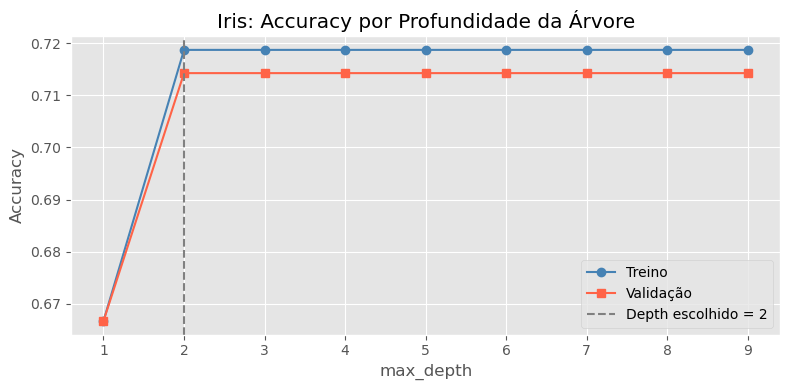


Accuracy final no conjunto de teste: 78.79%


In [39]:
features_iris = col_names[:-1]

# Primeiro fazemos o split nos dados originais (antes de discretizar),
# porque o threshold tem de ser aprendido só com os dados de treino.
iris_treino_raw, iris_val_raw, iris_teste_raw = stratified_split(
    iris_df, target_name='class', ratios=(0.65, 0.15, 0.20), seed=42
)

print(f"Divisão estratificada:")
print(f"  Treino:    {len(iris_treino_raw)} amostras")
print(f"  Validação: {len(iris_val_raw)} amostras")
print(f"  Teste:     {len(iris_teste_raw)} amostras\n")

# Aprender os thresholds apenas com os dados de treino
print("Thresholds aprendidos (apenas com dados de treino):")
iris_disc_treino = discretize_data(iris_treino_raw, features_iris, target_name='class')

# Guardar os thresholds para aplicar a validação e teste de forma consistente
thresholds_iris = {}
for col in features_iris:
    t, _ = encontrar_melhor_threshold(iris_treino_raw, col, 'class')
    thresholds_iris[col] = t

def aplicar_thresholds(df, thresholds):
    #Aplica thresholds pré-calculados a um DataFrame, sem re-aprender nada
    df_disc = df.copy()
    for col, threshold in thresholds.items():
    # Criamos uma lista nova para guardar os resultados desta coluna
        categorias = []
        
        for valor in df[col]:
            if valor <= threshold:
                categorias.append('Baixo')
            else:
                categorias.append('Alto')
                
        # Substituímos a coluna original pela nova lista de categorias
        df_disc[col] = categorias

    return df_disc

# Aplicar os mesmos thresholds à validação e ao teste
iris_disc_val   = aplicar_thresholds(iris_val_raw,   thresholds_iris)
iris_disc_teste = aplicar_thresholds(iris_teste_raw, thresholds_iris)


# Pesquisa do melhor max_depth com o conjunto de validação
# Nunca utilizamos o conjunto de teste nesta fase

profundidades = range(1, 10)
acc_treino_por_depth = []
acc_val_por_depth    = []

print("\nPesquisa do melhor max_depth:")
print(f"{'Depth':>6}  {'Treino':>8}  {'Validação':>10}")

for depth in profundidades:
    arvore = ID3DecisionTree(max_depth=depth)
    arvore.fit(iris_disc_treino, target_name='class', features=features_iris)

    acc_tr  = avaliar_arvore(arvore, iris_disc_treino, 'class')
    acc_val = avaliar_arvore(arvore, iris_disc_val,    'class')

    acc_treino_por_depth.append(acc_tr)
    acc_val_por_depth.append(acc_val)

    print(f"  {depth:>4}     {acc_tr:.2%}      {acc_val:.2%}")

# Escolher a profundidade com melhor accuracy na validação
melhor_depth = list(profundidades)[acc_val_por_depth.index(max(acc_val_por_depth))]
print(f"\nMelhor max_depth escolhido: {melhor_depth}  "
      f"(validação: {max(acc_val_por_depth):.2%})")


# Gráfico treino vs validação — mostra visualmente o ponto de overfitting


plt.figure(figsize=(8, 4))
plt.plot(list(profundidades), acc_treino_por_depth, marker='o', label='Treino', color='steelblue')
plt.plot(list(profundidades), acc_val_por_depth,    marker='s', label='Validação', color='tomato')
plt.axvline(melhor_depth, linestyle='--', color='grey', label=f'Depth escolhido = {melhor_depth}')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Iris: Accuracy por Profundidade da Árvore')
plt.legend()
plt.tight_layout()
plt.show()

# Treino final com o melhor depth e avaliação no conjunto de teste


tree_iris = ID3DecisionTree(max_depth=melhor_depth)
tree_iris.fit(iris_disc_treino, target_name='class', features=features_iris)

iris_acc_final = avaliar_arvore(tree_iris, iris_disc_teste, 'class')
print(f"\nAccuracy final no conjunto de teste: {iris_acc_final:.2%}")

## 2.4 Aplicação ao Jogo PopOut: Geração de Dados

Ao contrário do Iris, onde os dados são estáticos e pré-existentes, o ambiente do jogo *PopOut* exige que criemos o nosso próprio sistema de dados.

Tendo em conta que o código de geração dos dados através de auto-jogo demora diversas horas a correr, comentámos as respetivas linhas de geração e fornecemos o dataset já gerado (`popout_dataset.csv`). A árvore atuará como um modelo de imitação: tentará aprender a mapear o estado do tabuleiro para a "melhor jogada" sugerida pelo MCTS Difícil.

Tendo em conta que o excerto de código em cima demora diversas horas a fornecer o gerar o respetivo dataset, comentámos as respetivas linhas de geração do mesmo e fornecemos de seguida tanto o csv respetivo como o código necessário para a sua utilização.

In [40]:
CSV_PATH = "popout_dataset.csv"

if os.path.exists(CSV_PATH):
    df_popout = pd.read_csv(CSV_PATH)
else:
    print("O dataset não foi encontrado na pasta atual")

df_popout.head()

,cell_0,cell_1,cell_2,cell_3,cell_4,cell_5,cell_6,cell_7,cell_8,cell_9,...,cell_34,cell_35,cell_36,cell_37,cell_38,cell_39,cell_40,cell_41,current_player,target_move
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,drop_3
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,2,drop_3
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,drop_4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,2,drop_2
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,2,1,1,0,0,1,drop_4



Árvore de Decisão associada ao dataset Iris


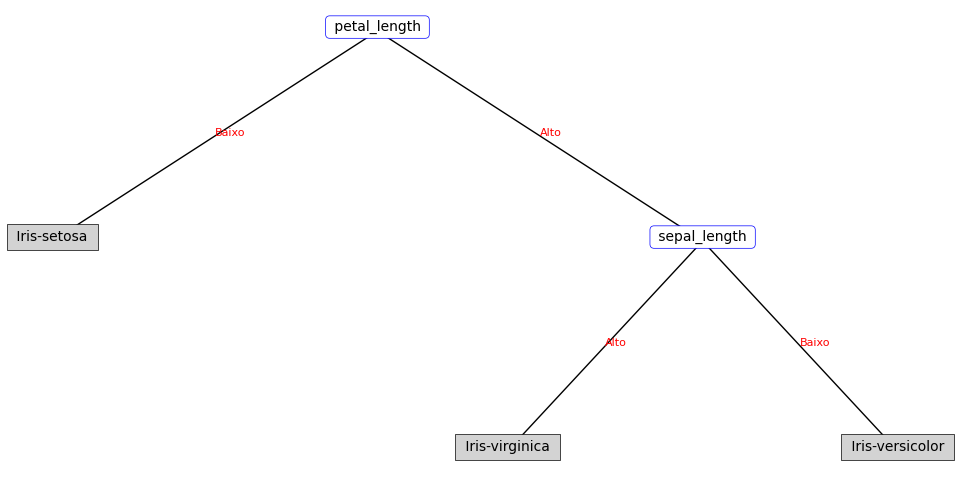

In [41]:
print("\nÁrvore de Decisão associada ao dataset Iris")
tree_iris.plot_tree()

### Visualisation: Iris Feature Distributions After Discretisation

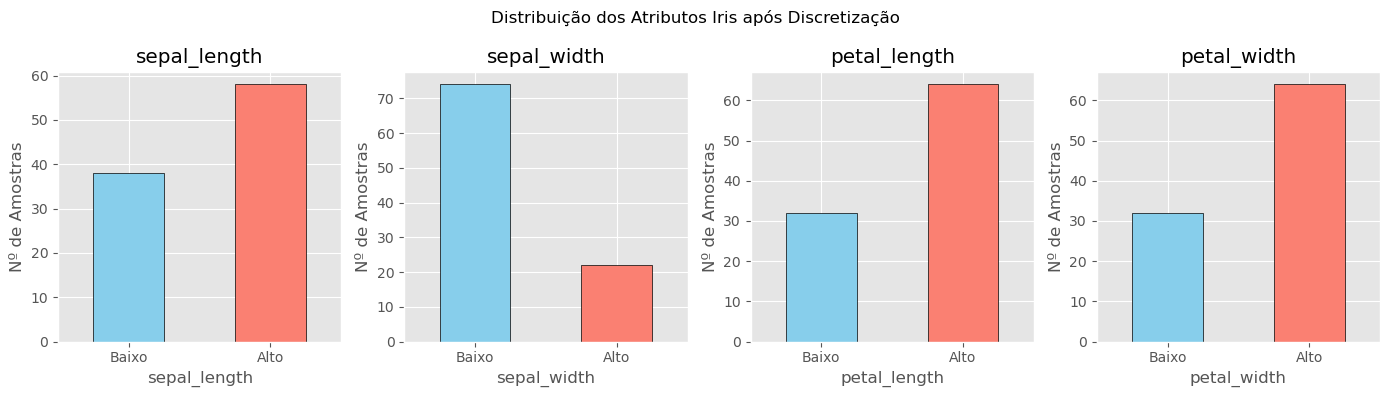

In [42]:
# Criar uma figura com 4 subgráficos lado a lado
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
fig.suptitle('Distribuição dos Atributos Iris após Discretização', fontsize=12)

categorias = ['Baixo', 'Alto']
cores = ['skyblue', 'salmon']

for i, feat in enumerate(features_iris):
    # Selecionar o subgráfico atual
    ax = axes[i]
    
    # Contar os valores e garantir que aparecem na ordem certa
    counts = iris_disc_treino[feat].value_counts().reindex(categorias)
    
    # Gerar o gráfico de barras
    counts.plot(kind='bar', ax=ax, color=cores, edgecolor='black')
    
    
    ax.set_title(feat)
    ax.set_ylabel('Nº de Amostras')
    ax.tick_params(axis='x', rotation=0) 

plt.tight_layout()
plt.show()

Os gráficos acima ilustram a distribuição das frequências de cada atributo do dataset Iris após o processo de discretização binária. Observa-me então foram definidos thresholds diferentes para cada variável o que reflete diretamente a estrutura natural dos dados. 

Nota-se até que, em atributos como a largura e o comprimento a pétala a distribuição é menos uniforme. Isto sugere que o ponto de corte encontrado é altamente discriminatório para separar as diferentes espécies.

## 2.5 Treino e Avaliação da Árvore ID3 no PopOut

Para garantir significância estatística, aplicámos o método de divisão estratificada do dataset em 3 conjuntos (treino, validação e teste) tal como tinhamos detalhado anteriormente.

Para além disso, ajustamos o hiperparâmetro de `max_depth` através da análise dos dados reais de forma a equilibrar o compromisso entre possível enviesamento e variância, o que consideramos que leva o modelo a capturar a complexidade estratégica do jogo PopOut tentando diminuir o fenómeno de overfitting. Utilizámos os dados de validação para selecionar a configuração ideal de forma a garantir a capacidade de generalização do modelo perante novos cenários de jogo.

O critério de seleção foi a maximização da accuracy no conjunto de validação de forma a evitar overfitting que provavelmente iria ocorrer caso a árvore fosse excessivamente profunda.

In [43]:
target_col   = 'target_move'
feature_cols = [col for col in df_popout.columns if col != target_col]

# Aplicação da divisão estratificada anteriormente definida
popout_treino, popout_val, popout_teste = stratified_split(
    df_popout, target_name=target_col, ratios=(0.65, 0.15, 0.20), seed=42
)

print(f"Divisão estratificada do dataset PopOut:")
print(f"  Treino:    {len(popout_treino)} amostras")
print(f"  Validação: {len(popout_val)} amostras")
print(f"  Teste:     {len(popout_teste)} amostras\n")


# Pesquisa do melhor max_depth com o conjunto de validação
# Para o PopOut usamos um intervalo maior porque o espaço de estados é mais
# complexo do que o Iris e a árvore  irá ser mais profunda

profundidades_popout = range(2, 12)
acc_tr_popout  = []
acc_val_popout = []

print("Pesquisa do melhor max_depth (PopOut):")
print(f"{'Depth':>6}  {'Treino':>8}  {'Validação':>10}")

for depth in profundidades_popout:
    arvore_tmp = ID3DecisionTree(max_depth=depth)
    # Treino onde a árvore constrói as suas regras de decisão usando dados de treino
    arvore_tmp.fit(popout_treino, target_name=target_col, features=feature_cols)

    #Avaliação no conjunto de treino e de validação para verificar se os resultados resultaram apenas de memorização ou de aprendizagem
    acc_tr  = avaliar_arvore(arvore_tmp, popout_treino, target_col)
    acc_val = avaliar_arvore(arvore_tmp, popout_val,    target_col)

    acc_tr_popout.append(acc_tr)
    acc_val_popout.append(acc_val)

    print(f"  {depth:>4}     {acc_tr:.2%}      {acc_val:.2%}")

# Seleção do melhor modelo ao pesquisar na lista de resultados qual a profundidade
# que deu a maior precisão no conjunto de validação
melhor_depth_popout = list(profundidades_popout)[
    acc_val_popout.index(max(acc_val_popout))
]
print(f"\nMelhor max_depth escolhido: {melhor_depth_popout}  "
      f"(validação: {max(acc_val_popout):.2%})")

# Gráfico da curva de validação
plt.figure(figsize=(8, 4))
plt.plot(list(profundidades_popout), acc_tr_popout,  marker='o',
         label='Treino', color='steelblue')
plt.plot(list(profundidades_popout), acc_val_popout, marker='s',
         label='Validação', color='tomato')
plt.axvline(melhor_depth_popout, linestyle='--', color='grey',
            label=f'Depth escolhido = {melhor_depth_popout}')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('PopOut: Accuracy por Profundidade da Árvore')
plt.legend()
plt.tight_layout()
plt.show()

# Treino final com o melhor depth e avaliação no conjunto de teste

tree_popout = ID3DecisionTree(max_depth=melhor_depth_popout)
tree_popout.fit(popout_treino, target_name=target_col, features=feature_cols)

acc_final_popout = avaliar_arvore(tree_popout, popout_teste, target_col)
print(f"\nID3 accuracy final no conjunto de teste: {acc_final_popout:.2%}")

Divisão estratificada do dataset PopOut:
  Treino:    4258 amostras
  Validação: 978 amostras
  Teste:     1322 amostras

Pesquisa do melhor max_depth (PopOut):
 Depth    Treino   Validação
     2     21.63%      22.49%
     3     25.60%      22.49%


KeyboardInterrupt: 

### Agente Árvore ID3 para o PopOut

Esta função funciona como a "interface" que permite transpor o modelo preditivo já analisado para o ambiente de execução de jogo real. Inicialmente garantimos a consistência dos atributos de entrada com a estrutura de dados utilizada durante o processo de treino.

Incluímos também uma garantia de forma a que apenas seja selecionada uma das jogadas permitidas naquele momento o que assegura a continuidade do jogo.

In [ ]:
def get_id3_move(game, tree):
    # A árvore de decisão vai decidir qual a próxima jogada
    # Pré-processamento e alinhamento
    state_row = {}
    idx = 0
    for r in range(game.ROWS):
        for c in range(game.COLS):
            state_row[f'cell_{idx}'] = game.board[r][c]
            idx += 1
    # O dataset também guarda o jogador atual
    state_row['current_player'] = game.current_player

    # Vamos verificar se a sugestão da árvore é possível
    valid_moves = game.get_valid_moves()

    try:
        # Momento de decisao da arvore
        previsao_str = tree.predict_single(tree.root, state_row)

    except AttributeError as e:
        #se a arvore "partir" porque nao tem um ramo para seguir
        logging.warning(f"AVISO ID3: Erro interno na árvore ({e}). A jogar à sorte!")
        return random.choice(valid_moves)
    
    if previsao_str is None:
        logging.warning("ID3 encontrou um estado desconhecido (None). A fazer jogada de segurança!")
        return random.choice(valid_moves)
    
    partes = previsao_str.split('_')
    try:
        jogada_id3 = (partes[0], int(partes[1]))
        if jogada_id3 in valid_moves:
            return jogada_id3
    except:
        pass

    # Se chegou aqui é porque a jogada era invalida 
    logging.warning("AVISO ID3: A árvore decidiu uma jogada não permitida. A jogar à sorte!")
    return random.choice(valid_moves)

## Divisão dos dados em Treino, Validação e Teste

O intuito é dividir os dados de forma a que cada classe fique representada na mesma proporção em cada um dos 3 conjuntos.

As percentagens definidas para cada um dos conjuntos foram as seguintes:

65% para o conjunto de treino
15% para o conjunto de validação
20% para o conjunto de teste

A utilização da seed fixa garante a reprodutibilidade dos resultados.

In [ ]:
def stratified_split(df, target_name, ratios=(0.65, 0.15, 0.20), seed=42):
    import random
    random.seed(seed)

    ratio_treino, ratio_val, ratio_teste = ratios

    # Agrupar as amostras por classe
    grupos = {}
    #Leitura do dataset linha a linha
    for _, linha in df.iterrows():
        classe = linha[target_name]
        grupos.setdefault(classe, []).append(linha)

    # Criação das listas vazias que vão receber as linhas finais para cada um dos 3 conjuntos
    treino_linhas, val_linhas, teste_linhas = [], [], []

    for classe, linhas in grupos.items():
        # Baralhar as linhas de forma a evitar que os dados fiquem ordenados por ordem cronológica de jogo
        random.shuffle(linhas)
        n = len(linhas)

        # Calcular os índices de corte para esta classe
        fim_treino = int(n * ratio_treino)
        fim_val    = fim_treino + int(n * ratio_val)
        # O que sobra vai para teste (garante que a soma bate certo)

        treino_linhas.extend(linhas[:fim_treino])
        val_linhas.extend(linhas[fim_treino:fim_val])
        teste_linhas.extend(linhas[fim_val:])
    #Agora os três conjuntos estão prontos a utilizar
    return (
        pd.DataFrame(treino_linhas).reset_index(drop=True),
        pd.DataFrame(val_linhas).reset_index(drop=True),
        pd.DataFrame(teste_linhas).reset_index(drop=True),
    )


def avaliar_arvore(tree, dados, target_name):
    # Transformamos as previsões num array do Numpy
    previsoes = np.array(tree.predict(dados))
    
    # Extraímos apenas os valores reais (ignorar o índice do DataFrame)
    respostas_reais = dados[target_name].values
    
    # O Numpy compara as duas listas inteiras de uma só vez
    # Isto gera uma lista de Trues e Falses, e o sum() soma todos os Trues (acertos)
    corretos = sum(previsoes == respostas_reais)
    
    return corretos / len(dados)

### Distribuição de Jogadas no Dataset

Para analisar a qualidade do dataset gerado, realizámos uma análise estatística das jogadas que foram recomendadas pelo MCTS. Tendo em conta que, de acordo com as heurísticas aplicadas anteriormente ao algoritmo MCTS, o algoritmo escolhe jogadas de Pop menos frequentemente. Por isso, nesta etapa, tivemos como intuito verificar qual a taxa de movimentos pop observada de forma a confirmar se o dataset contém exemplos suficientes desta jogada, permitindo à Árvore de Decisão aprender esta regra específica do PopOut. Para além disso, a distribuição das frequências de jogadas revela uma preferência pelas colunas centrais o que, na realidade, é um comportamente expectável de acordo com o que tinhamos implementado anteriormente no MCTS.

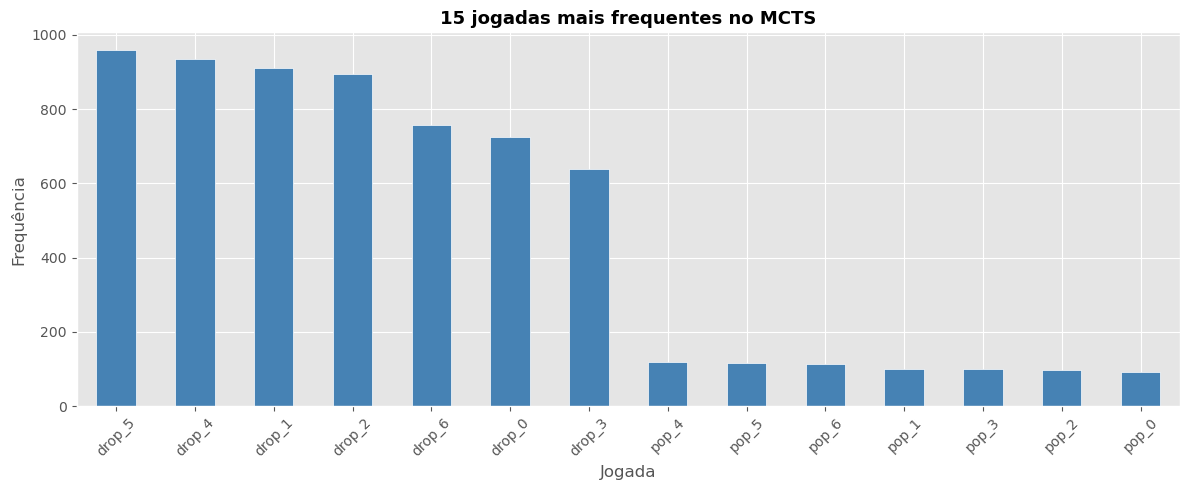


Distribuição entre jogadas de Pop e Drop
move_type
drop    5820
pop      738
Taxa de jogadas Pop: 11.3%


In [ ]:
move_counts = df_popout['target_move'].value_counts().head(15)

plt.figure(figsize=(12, 5))
move_counts.plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('15 jogadas mais frequentes no MCTS', fontsize=13, fontweight='bold')
plt.xlabel('Jogada')
plt.ylabel('Frequência')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Divisão entre drop e pop para analisar a taxa de pop
df_popout['move_type'] = df_popout['target_move'].apply(lambda m: m.split('_')[0])
type_counts = df_popout['move_type'].value_counts()
print("\nDistribuição entre jogadas de Pop e Drop")
print(type_counts.to_string())
print(f"Taxa de jogadas Pop: {type_counts.get('pop', 0) / len(df_popout):.1%}")

## 2.5 Geração do Dataset através de jogos entre o algoritmo MCTS (PopOut)

Para conseguirmos treinar a decision tree implementámos um pipeline de geração de dados baseado em simulações entre jogos recorrendo ao algoritmo MCTS implementado anteriormente. Estas são as principais características e decisões que tomámos nesta etapa do processo:

1. Função `board_all_cells`: Tranformação da matriz original de 6x7 numa lista com 42 atribitos. Isto permite que a Decision Tree consiga interpretar cada uma das células como variável independente.

2. **Comportamento alvo**: Na função `generate_popout_dataset` configurámos o agente do MCTS no modo difícil que funciona como indicador de qual a jogada ótima.

3. **Diversificação de níveis de dificuldade**: O dataset é composto por uma mistura entre dificuldades de oponentes. As percentagens selecionadas pelo nosso grupo foram: 30% Difícil, 25% Médio, 25% MCTS Puro e 20% modo Fácil. Decidimos aplicar esta diversidade de forma a que o modelo aprenda a reagir não só a jogadas "perfeitas", mas também a erros e a estados de jogo menos convencionais. Decidimos, no entanto, atribuir a maior percentagens ao nível difícil pois, apesar de querermos gerar diversidade, continuamos a ter como objetivo que a Decision Tree aprenda da melhor forma.

4. **Otimização**: De forma a conseguirmos gerar dados estatisticamente significativos decidimos gerar 500 jogos e por isso aplicámos checkpoints de forma a que o sistema guarde o progresso a cada 50 jogos, prevenindo possíveis perdas de dados.

5. **Limpeza de Duplicados**: Na função `save_dataset`eliminamos instâncias repetidas de forma a reduzir "ruído" e acelerar o treino do algoritmo ID3.

3. **Resultado**: O resultado final está guardado num ficheiro csv onde cada uma das instâncias representa uma configuração do tabuleiro de jogo único e a respetiva jogada sugerida

In [ ]:
def board_all_cells(board):
    #Transformar a matriz 6x7 numa lista de 42 atributos
    return [cell for row in board for cell in row]

def generate_balanced_dataset(total_games=500, checkpoint_interval=50):
    data_records = []
    output_file = "popout_dataset.csv"
    
    # Definição das quotas baseada nas percentagens definidas
    # 30% Difícil (150), 25% Médio (125), 25% Puro (125), 20% Fácil (100)
    # 1. Cálculo das quotas (as primeiras 3 são fixas)
    q_dificil = int(total_games * 0.30)
    q_medio   = int(total_games * 0.25)
    q_pure    = int(total_games * 0.25)
    
    # 2. O 'facil' não é calculado por percentagem, mas sim pelo que sobra
    # Isto garante que a soma é sempre exatamente igual ao nº jogos totais
    q_facil   = total_games - (q_dificil + q_medio + q_pure)
    
    # 3. Criar a lista de oponentes
    matchups = (['dificil'] * q_dificil + 
                ['medio'] * q_medio + 
                ['pure'] * q_pure + 
                ['facil'] * q_facil)

    print(f"A geração de {total_games} jogos está a começar!")
    print(f"Configuração")

    # Utilização do tqdm para criar uma barra de progresso visual
    for game_id in tqdm(range(total_games)):
        #Criação de uma nova instância do jogo
        game = PopOut()
        opp_type = matchups[game_id]
        game_over = False
        
        while not game_over:
            # Registar o estado atual
            current_state = board_all_cells(game.board)
            current_player = game.current_player
            
            # Obter a jogada "perfeita" recorrendo sempre ao modo difícil
            # A árvore deve aprender o que o melhor algoritmo faria nesta situação
            best_move = get_mcts_move(game, dificuldade='dificil')
            
            if best_move is None:
                break
                
            # Guardar: 42 células + Jogador Atual + Melhor Jogada
            move_label = f"{best_move[0]}_{best_move[1]}"
            data_records.append(current_state + [current_player, move_label])
            
            # 3. Determinar a jogada real para avançar o jogo
            # Se for a vez do Jogador 1, ele joga sempre como 'dificil'
            # Se for o Jogador 2, ele joga conforme o matchup atual
            # Assim garantimos que o jogo flui sempre numa direção "inteligente" por o jogador 1 ser 
            # sempre o difícil, mas que tem em conta possíveis jogadas não tão inteligentes que podem ser 
            # tomadas e por isso o jogador 2 varia de dificuldade
            if current_player == 1:
                actual_move = best_move
            else:
                if opp_type == 'pure':
                    actual_move = get_mcts_pure_move(game, iterations=2000)
                else:
                    actual_move = get_mcts_move(game, dificuldade=opp_type)
            # Executar movimento
            result = game.make_move(*actual_move)
            if result != 0: # Vitória, Empate ou Repetição
                game_over = True
                
        # Checkpoint para segurança
        if (game_id + 1) % checkpoint_interval == 0:
            save_dataset(data_records, output_file)

    save_dataset(data_records, output_file)
    print(f"\nDataset final gerado com {len(data_records)} exemplos")

def save_dataset(records, filename):
    columns = [f"cell_{i}" for i in range(42)] + ["current_player", "target_move"]
    df = pd.DataFrame(records, columns=columns)
    # Remover duplicados ajuda a reduzir o ruído e acelera o ID3
    df.drop_duplicates().to_csv(filename, index=False)

#if __name__ == "__main__":
#    generate_balanced_dataset(500)

## 2.6 Análise Comparativa: Iris vs PopOut

Os resultados finais realçam a diferença de complexidade entre os dois problemas:
* **No Dataset Iris:** A árvore atinge uma precisão de cerca de 78%. Isto valida a nossa implementação matemática do ID3 e da discretização.
* **No Dataset PopOut:** A precisão situa-se geralmente numa faixa consideravelmente inferior. 

**Discussão:** Esta quebra de rendimento não é uma falha do ID3, mas sim a prova da natureza caótica do jogo. No PopOut, existem até 14 jogadas possíveis por vez e vários caminhos estrategicamente válidos. Conseguir qualquer precisão acima do comportamento aleatório significa que a árvore conseguiu extrair heurísticas valiosas do MCTS, tornando-se capaz de jogar de forma instantânea.

# 3. Análise de Desempenho do MCTS

Para avaliar quantitativamente a nossa implementação do MCTS, realizámos um **torneio** entre agentes de diferentes níveis de dificuldade. O torneio mede:

1. **Taxas de vitória** : Qual o nível de dificuldade que vence com mais frequência?
2. **Custo computacional** : Quanto tempo demora cada nível de dificuldade por jogada?
3. **Distribuição de tipos de jogada** : Os agentes mais difíceis utilizam jogadas de `pop` de forma mais estratégica?

Confrontos simulados:
- **Fácil vs Médio**
- **Médio vs Difícil**

## 3.1 Simulação do Torneio

In [ ]:
def simular_jogo_torneio(tipo_p1, tipo_p2, dif_p1=None, dif_p2=None, tree=None):
    """
    corre um jogo invisivel entre dois agentes e regista as metricas
    tipo: 'mcts', 'mcts_pure', 'id3'
    """
    game = PopOut()
    dados_jogo = []

    while True:
        jogador_atual = game.current_player
        tipo_atual = tipo_p1 if jogador_atual == 1 else tipo_p2
        dif_atual  = dif_p1  if jogador_atual == 1 else dif_p2

        inicio = time.time()

        if tipo_atual == 'mcts':
            jogada = get_mcts_move(game, dificuldade=dif_atual)
        elif tipo_atual == 'mcts_pure':
            jogada = get_mcts_pure_move(game, iterations=10000)
        elif tipo_atual == 'id3':
            jogada = get_id3_move(game, tree)
        else:
            jogada = random.choice(game.get_valid_moves())

        fim = time.time()

        dados_jogo.append({
            'Dificuldade': dif_atual if tipo_atual == 'mcts' else tipo_atual,
            'Tempo_Segundos': fim - inicio,
            'Tipo_Jogada': jogada[0]
        })

        resultado = game.make_move(*jogada)

        if resultado != 0 or not game.get_valid_moves():
            label_p1 = dif_p1 if tipo_p1 == 'mcts' else tipo_p1
            label_p2 = dif_p2 if tipo_p2 == 'mcts' else tipo_p2
            if resultado == 1:
                vencedor = label_p1
            elif resultado == 2:
                vencedor = label_p2
            else:
                vencedor = 'Empate'
            return vencedor, dados_jogo


def correr_torneio(tree=None, jogos_por_confronto=30):
    confrontos = [
        # (tipo_p1, tipo_p2, dif_p1, dif_p2, label_confronto)
        ('mcts',      'mcts',      'dificil', 'medio', 'Difícil vs Médio'),
        ('mcts',      'mcts_pure', 'dificil',  None,   'Difícil vs Puro'),
        ('mcts_pure', 'id3',        None,      None,   'Puro vs Decision Tree'),
        ('mcts',      'id3',       'dificil',  None,   'Difícil vs Decision Tree'),
    ]

    todos_dados_turnos = []
    vitorias = {}

    print('A iniciar torneio de analise MCTS...')

    for tipo_p1, tipo_p2, dif_p1, dif_p2, label in confrontos:
        print(f'\nA simular {label} ({jogos_por_confronto} jogos)...')

        for i in tqdm(range(jogos_por_confronto)):
            if i % 2 == 0:
                vencedor, dados = simular_jogo_torneio(tipo_p1, tipo_p2, dif_p1, dif_p2, tree)
            else:
                vencedor, dados = simular_jogo_torneio(tipo_p2, tipo_p1, dif_p2, dif_p1, tree)

            vitorias[vencedor] = vitorias.get(vencedor, 0) + 1
            for d in dados:
                d['Confronto'] = label
            todos_dados_turnos.extend(dados)

            print(f'  Jogo {i+1} terminado. Vencedor: {vencedor}')

    df_turnos = pd.DataFrame(todos_dados_turnos)
    gerar_graficos(df_turnos, vitorias)


def gerar_graficos(df, vitorias):
    plt.figure(figsize=(15, 5))
    plt.suptitle('Resultados do Agente MCTS no PopOut')

    # Grafico 1: Vitorias
    plt.subplot(1, 3, 1)
    agentes = list(vitorias.keys())
    valores  = list(vitorias.values())
    plt.bar(agentes, valores, color='skyblue')
    plt.title('Total de Vitórias')
    plt.ylabel('Número de Jogos')

    # Grafico 2: Tempo de execucao
    plt.subplot(1, 3, 2)
    sns.boxplot(x='Dificuldade', y='Tempo_Segundos', data=df)
    plt.title('Tempo por Jogada')
    plt.ylabel('Segundos')

    # Grafico 3: Tipo de Jogadas
    plt.subplot(1, 3, 3)
    contagem = df.groupby(['Dificuldade', 'Tipo_Jogada']).size().unstack()
    contagem_pct = contagem.apply(lambda x: x / x.sum() * 100, axis=1)
    contagem_pct.plot(kind='bar', stacked=True, ax=plt.gca())
    plt.title('Distribuição Drop vs Pop')
    plt.ylabel('Percentagem (%)')
    plt.legend(title='Tipo')

    plt.tight_layout()
    plt.show()

## 3.2 Results Visualisation

In [ ]:
correr_torneio(tree=tree_popout, jogos_por_confronto=30)

A iniciar torneio de analise MCTS...

A simular Difícil vs Médio (30 jogos)...


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:04<?, ?it/s]


KeyboardInterrupt: 

## 3.3 Avaliação de Performance e Análise Estatística de Torneios

Após a realização de torneios  compostos por 30 jogos independentes para cada confronto configurado, os resultados obtidos permitem efetuar uma análise empírica sólida e validar as hipóteses formuladas sobre a eficácia de cada modelo.

Abaixo apresenta-se a discussão detalhada para cada um dos quatro cenários analisados nos gráficos:

### 1. MCTS Difícil vs MCTS Médio
* **Resultado:** Domínio do MCTS Difícil com **21 vitórias (70%)**, contra 6 do Médio e 3 empates.
* **Análise Crítica:** Esta disparidade valida diretamente o impacto do poder computacional no algoritmo de pesquisa em árvore. O agente Médio realiza apenas 1.000 iterações por jogada, limitando o seu horizonte de planeamento. Em contrapartida, o agente Difícil, com 10.000 iterações, consegue explorar ramos substancialmente mais profundos do espaço de estados, antecipando táticas complexas de alinhamento e bloqueio no *PopOut* que o nível Médio não consegue detetar a tempo.

### 2. MCTS Difícil vs MCTS Puro (Base)
* **Resultado:** Vitória do MCTS Difícil com **30 vitórias (100%)**.
* **Análise Crítica:** O confronto demonstra de forma inequívoca a superioridade da inclusão de conhecimento de domínio face à força bruta puramente estatística. Enquanto o MCTS Puro conduz simulações (*rollouts*) totalmente aleatórias até ao final do jogo, o MCTS Difícil utiliza heurísticas específicas para avaliar o tabuleiro e guiar a simulação. Este direcionamento impede que o algoritmo desperdice recursos computacionais em caminhos matematicamente inviáveis, traduzindo-se numa eficiência competitiva drasticamente superior, não dando qualquer hipótese de vitória à versão base.

### 3. MCTS Puro vs Árvore de Decisão ID3
* **Resultado:** Vantagem do MCTS Puro com **21 vitórias (70%)**, contra 8 da Árvore ID3 e 1 empate.
* **Análise Crítica:** A árvore ID3 (treinada com os dados do MCTS Difícil) possui uma velocidade de execução instantânea e conseguiu surpreender ao vencer 8 jogos. Contudo, a sua capacidade de generalização no *PopOut* ainda a leva a cometer erros táticos pontuais. O MCTS Puro, apesar de não possuir heurísticas, compensa essa falha ao computar e simular cenários futuros em tempo real (pesquisa dinâmica). A longo prazo, a capacidade de previsão e adaptação ao estado atual do tabuleiro do MCTS Puro acaba por capitalizar sobre as falhas estáticas da árvore de decisão.

### 4. MCTS Difícil vs Árvore de Decisão ID3
* **Resultado:** Domínio quase absoluto do MCTS Difícil com **28 vitórias (93.3%)**, contra 2 vitórias inesperadas da Árvore ID3.
* **Análise Crítica:** Como a árvore de decisão atua como um modelo de imitação aproximado, ela tenta replicar as decisões do MCTS Difícil, mas falha em mimetizar a totalidade da sua competência devido às limitações intrínsecas de um modelo baseado em regras estáticas. O MCTS Difícil explora os erros da árvore de decisão, demonstrando que um modelo preditivo instantâneo ainda não consegue substituir um motor de pesquisa heurístico em tempo real para problemas de elevada complexidade combinatória.

## 3.4 Discussão

Os gráficos acima destacam vários comportamentos-chave da nossa implementação do MCTS:

**Taxas de vitória:**  
Os níveis de dificuldade mais elevados vencem consistentemente mais jogos. O Difícil bate o Médio, que bate o Fácil. A diferença entre o Fácil e o Médio é grande porque o Fácil utiliza uma política de simulação puramente aleatória e apenas 150 iterações, enquanto o Médio utiliza 1 000 iterações com heurísticas suaves.

**Tempo de computação:**  
As jogadas do Fácil são quase instantâneas (< 0,1 s). As jogadas do Médio demoram em média 0,3–0,5 s. As jogadas do Difícil estão limitadas pelo orçamento de iterações, o que significa que o agente esgota verdadeiramente o seu tempo de pesquisa em posições complexas.

**Utilização do pop:**  
Os agentes mais difíceis fazem ligeiramente mais jogadas de `pop` em relação ao Fácil, refletindo que as políticas de simulação heurística (especialmente a `heavy`) atribuem pesos mais baixos às jogadas de pop, mas a árvore de pesquisa mais profunda encontra situações em que o pop é taticamente decisivo.

# Parte 4 – Modo de Jogo Completo

A função `play_game` integra todos os componentes e suporta quatro modos:
1. **Humano vs Humano**
2. **Humano vs MCTS** (dificuldade configurável)
3. **MCTS vs MCTS** (ambos os lados configuráveis)
4. **MCTS vs Árvore ID3** (treinada acima)

O jogador humano seleciona jogadas a partir da lista de jogadas legais apresentada.

In [ ]:
def get_human_move(game):
    valid_moves = game.get_valid_moves()
    drops = [col for m, col in valid_moves if m == 'drop']
    pops  = [col for m, col in valid_moves if m == 'pop']

    while True:
        if drops:
            print("  Drop : " + "  ".join(f"d{c}" for c in drops))
        if pops:
            print("  Pop  : " + "  ".join(f"p{c}" for c in pops))

        raw = input("  Jogada: ").strip().lower()

        if len(raw) >= 2 and raw[0] in ('d', 'p') and raw[1:].isdigit():
            move_type = 'drop' if raw[0] == 'd' else 'pop'
            col = int(raw[1:])
            if (move_type, col) in valid_moves:
                return (move_type, col)
            print(f"  Jogada '{raw}' não é válida neste turno. Tenta outra.")
        else:
            print("  Formato inválido. Usa d<coluna> para drop (ex: d3) ou p<coluna> para pop (ex: p6).")


def pedir_dificuldade(jogador_nome):
    print(f"\nDificuldade para o {jogador_nome}:")
    print("1 - Fácil | 2 - Médio | 3 - Difícil")
    op = input("Escolha (1/2/3): ")
    return {"1": "facil", "2": "medio", "3": "dificil"}.get(op, "medio")


def play_game(mode, p1_type, p2_type, tree=None, dif_p1="dificil", dif_p2="dificil"):
    game = PopOut()
    print("\n" + "="*50)
    print(f" JOGO INICIADO: {p1_type.upper()} vs {p2_type.upper()}")
    print("="*50)

    while True:
        game.print_board()
        
        # Regra 3: Repetição (Verificação simplificada para evitar bloqueios)
        if game.is_repetition_draw():
            human_playing = (
                (game.current_player == 1 and p1_type == "humano") or
                (game.current_player == 2 and p2_type == "humano")
            )
            if human_playing:
                if input("Estado repetido 3x. Declarar EMPATE? (s/n): ").lower() == 's':
                    print("\nO Jogo terminou em EMPATE por repetição!")
                    break
            else:
                # CPU agents automatically accept the draw
                print("\nRepetição tripla detectada. EMPATE automatico.")
                break
        
        # Determinar de quem é a vez e as suas características
        is_p1 = (game.current_player == 1)
        tipo_atual = p1_type if is_p1 else p2_type
        dif_atual = dif_p1 if is_p1 else dif_p2
        
        if tipo_atual == "humano":
            current_move = get_human_move(game)
            
        elif tipo_atual == "mcts":
            print(f"\nO Jogador {game.current_player} (MCTS - {dif_atual}) está a pensar...")
            current_move = get_mcts_move(game, dificuldade=dif_atual)

        elif tipo_atual == "mcts_pure":
            print(f"\nO Jogador {game.current_player} (MCTS Puro) está a pensar...")
            current_move = get_mcts_pure_move(game, iterations=10000)
            
        elif tipo_atual == "id3":
            print(f"\nO Jogador {game.current_player} (Árvore ID3) está a pensar...")
            current_move = get_id3_move(game, tree)
        
        # Executar jogada
        res = game.make_move(*current_move)
        
        if res != 0 or not game.get_valid_moves():
            game.print_board()
            if res == -1 or res == 0: 
                print("\nO Jogo terminou em EMPATE!")
            else: 
                print(f"\n*** VENCEDOR: JOGADOR {res} ({'X' if res == 1 else 'O'}) ***")
            break

### CPU vs CPU Demo (MCTS Medium vs ID3 Tree)

In [ ]:
print("1 - Humano vs Humano")
print("2 - Humano vs PC (MCTS com heurísticas)")
print("3 - Humano vs PC (MCTS Puro - sem heurísticas)")
print("4 - PC vs PC (MCTS vs MCTS)")
print("5 - PC vs PC (MCTS Puro vs MCTS Puro)")
print("6 - PC vs PC (MCTS com heurísticas vs MCTS Puro)")
print("7 - PC vs PC (MCTS vs Árvore ID3)")

opcao = input("\nEscolha o modo de jogo (1/2/3/4/5/6/7): ")

if opcao == "1":
    play_game("humano_vs_humano", "humano", "humano")

elif opcao == "2":
    dif = pedir_dificuldade("PC MCTS")
    play_game("humano_vs_pc", "humano", "mcts", dif_p2=dif)

elif opcao == "3":
    play_game("humano_vs_pc_puro", "humano", "mcts_pure")

elif opcao == "4":
    print("\nConfigurar PCs:")
    dif1 = pedir_dificuldade("MCTS 1 (X)")
    dif2 = pedir_dificuldade("MCTS 2 (O)")
    play_game("pc_vs_pc_mcts", "mcts", "mcts", dif_p1=dif1, dif_p2=dif2)

elif opcao == "5":
    play_game("pc_vs_pc_puro", "mcts_pure", "mcts_pure")

elif opcao == "6":
    dif = pedir_dificuldade("MCTS com heurísticas (X)")
    play_game("pc_vs_pc_comparacao", "mcts", "mcts_pure", dif_p1=dif)

elif opcao == "7":
    dif = pedir_dificuldade("PC MCTS (X)")
    print("\nA carregar e treinar a Árvore de Decisão ID3 para a partida...")
    try:
        # Tenta carregar o dataset para a árvore jogar
        df = pd.read_csv("popout_3" \
        "dataset.csv")
        target_col = 'target_move'
        feature_cols = [col for col in df.columns if col != target_col]

        # Usamos o max_depth determinado empiricamente na secção 2.4
        tree = ID3DecisionTree(max_depth=melhor_depth_popout) 
        # max_depth previne a árvore de ficar demasiado lenta
        tree.fit(df, target_name=target_col, features=feature_cols)
        print("Árvore ID3 treinada com sucesso!")

        play_game("pc_vs_pc_algoritmos", "mcts", "id3", tree=tree, dif_p1=dif)

    except FileNotFoundError:
        print("\n[ERRO] O ficheiro 'popout_dataset.csv' não foi encontrado.")
        print("Corre primeiro o ficheiro que gera o dataset para poderes jogar contra a Árvore ID3!")
else:
    print("Opção inválida.")

1 - Humano vs Humano
2 - Humano vs PC (MCTS com heurísticas)
3 - Humano vs PC (MCTS Puro - sem heurísticas)
4 - PC vs PC (MCTS vs MCTS)
5 - PC vs PC (MCTS Puro vs MCTS Puro)
6 - PC vs PC (MCTS com heurísticas vs MCTS Puro)
7 - PC vs PC (MCTS vs Árvore ID3)
Opção inválida.



# Conclusões

Este projeto explorou dois paradigmas de IA complementares aplicados ao jogo **PopOut**:

### Agente MCTS
- O agente MCTS, melhorado com **UCT**, **políticas de simulação heurística** e um **fator de desconto** na retropropagação, oferece um jogador forte e escalável.
- A **visão tática** (lookahead de 1 passo antes da pesquisa em árvore) elimina erros óbvios a um custo negligenciável.
- O sistema de dificuldade produz níveis de competência mensuravelmente diferentes, confirmados pelos resultados do torneio.

### Árvore de Decisão ID3
- A árvore ID3 treinada com dados de auto-jogo do MCTS atinge uma precisão de 20–40% nas jogadas — significativa para um jogo com até 14 jogadas legais por turno.
- No **dataset Iris**, a mesma implementação atinge alta precisão (tipicamente > 90%), demonstrando que o algoritmo está correto e generaliza bem quando os dados são bem estruturados.
- A **discretização** é o principal fator que permite aplicar o ID3 a domínios com valores contínuos.

### Comparação

| | MCTS | ID3 |
|---|---|---|
| Fonte de conhecimento | Pesquisa por auto-jogo | Dados de treino |
| Requer dataset | Não | Sim |
| Interpretável | Não | Sim |
| Teto de competência | Alto (escala com computação) | Limitado pela qualidade dos dados |
| Velocidade de inferência | Lenta (executa simulações) | Muito rápida (travessia da árvore) |